# 02 · Front-end facial: detección, ROIs y extracción

Esta notebook muestra, paso a paso, la primera etapa que procesa los videos. La comparten los dos enfoques:

| Módulo | Qué hace |
|---|---|
| `rppg.face.landmarker` | Detecta 478 landmarks faciales por frame con MediaPipe Face Landmarker (decisión D1). |
| `rppg.face.roi` | Define las ROIs de piel (frente y mejillas) a partir de los landmarks, calcula su color medio y recorta la cara para el DL. |
| `rppg.face.extract` | Recorre cada video una sola vez y guarda trazas RGB por ROI (clásico) y recortes de cara (DL). |

Todos los parámetros salen de `configs/face.yaml`. La lógica vive en `rppg`; acá solo se usa y se grafica.

**Requisitos:** UBFC-rPPG en `data/raw/`. Para la sección 4, haber corrido `uv run python scripts/extract_traces.py`.

In [1]:
from itertools import islice
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rppg.data.ubfc import UBFCrPPG
from rppg.dsp.filters import bandpass
from rppg.dsp.resample import resample_uniform
from rppg.dsp.spectral import estimate_rate
from rppg.eval.metrics import summarize
from rppg.face.extract import extract_video, load_traces
from rppg.face.landmarker import MonotonicClock, VideoLandmarker, ensure_model
from rppg.face.roi import face_crop, polygon_mask, roi_means, skin_mask
from rppg.utils.config import load_yaml

ROOT = Path("..").resolve()
cfg = load_yaml(ROOT / "configs" / "face.yaml")
model = ensure_model(ROOT / cfg["model"]["path"], cfg["model"]["url"], cfg["model"]["sha256"])
ds = UBFCrPPG(ROOT / cfg["dataset"]["root"])
ROIS = cfg["rois"]
ROI_COLORS = {"forehead": (255, 80, 80), "left_cheek": (80, 220, 80), "right_cheek": (80, 140, 255)}
FS = 30.0
HR_BAND = (0.7, 4.0)

print("Modelo:", model.relative_to(ROOT), "(SHA-256 verificado)")
print("ROIs:", {k: len(v) for k, v in ROIS.items()}, "landmarks por polígono")

Modelo: models\face_landmarker.task (SHA-256 verificado)
ROIs: {'forehead': 12, 'left_cheek': 14, 'right_cheek': 14} landmarks por polígono


## 1. Detección de landmarks (`landmarker.py`)

### 1.1 Por qué hace falta `MonotonicClock`

En modo VIDEO, MediaPipe aprovecha la detección del frame anterior para seguir la cara, y para eso **exige timestamps estrictamente crecientes**. UBFC-rPPG trae timestamps repetidos: intervalos de 0 ms entre frames consecutivos. Pasarlos tal cual hace fallar al detector con `Input timestamp must be monotonically increasing`. `MonotonicClock` los convierte a milisegundos y, si uno se repite o retrocede, lo adelanta 1 ms.

In [2]:
rows = []
for s in ds.subjects():
    t = ds.ground_truth(s).t
    ms = np.round(t * 1000).astype(int)
    rows.append({"subject": s, "repeated_ms": int((np.diff(ms) <= 0).sum())})
repeated = pd.DataFrame(rows).set_index("subject")
print(f"Sujetos con timestamps repetidos: {(repeated.repeated_ms > 0).sum()} de {len(repeated)}")
print(f"Máximo por video: {repeated.repeated_ms.max()} frames")

clock = MonotonicClock()
demo = [0.0, 0.033, 0.033, 0.030, 0.100]
print("\nEjemplo:", demo, "->", [clock(t) for t in demo], "ms")

Sujetos con timestamps repetidos: 9 de 42
Máximo por video: 3 frames

Ejemplo: [0.0, 0.033, 0.033, 0.03, 0.1] -> [0, 33, 34, 35, 100] ms


### 1.2 Landmarks sobre un frame

Una instancia de `VideoLandmarker` por video, porque los timestamps tienen que crecer dentro de la misma instancia. Devuelve un arreglo `(478, 2)` en píxeles, o `None` si no encuentra cara.

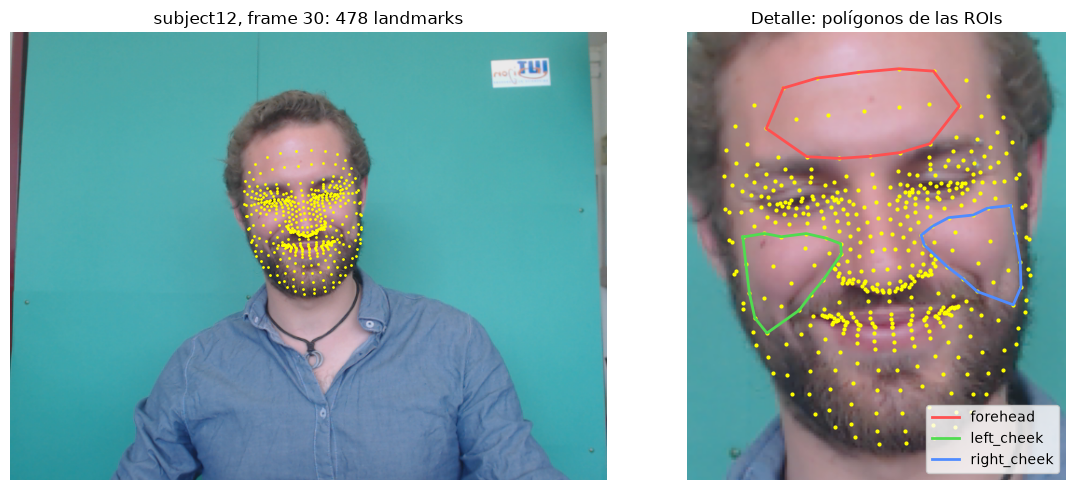

In [3]:
subject = "subject12"
gt = ds.ground_truth(subject)
with VideoLandmarker(model) as detector:
    for i, frame in enumerate(islice(ds.frames(subject), 31)):
        landmarks = detector(frame, gt.t[i])

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(frame)
ax[0].scatter(*landmarks.T, s=1, c="yellow")
ax[0].set_title(f"{subject}, frame 30: {len(landmarks)} landmarks")
x0, y0 = landmarks.min(axis=0) - 15
x1, y1 = landmarks.max(axis=0) + 15
ax[1].imshow(frame)
ax[1].scatter(*landmarks.T, s=4, c="yellow")
for name, idx in ROIS.items():
    poly = np.vstack([landmarks[idx], landmarks[idx[:1]]])
    ax[1].plot(*poly.T, c=np.array(ROI_COLORS[name]) / 255, lw=2, label=name)
ax[1].set(xlim=(x0, x1), ylim=(y1, y0), title="Detalle: polígonos de las ROIs")
ax[1].legend(loc="lower right")
for a in ax:
    a.axis("off")
plt.tight_layout()

### 1.3 Suavizado de landmarks

Aunque la cabeza esté quieta, los landmarks tiemblan unos décimos de píxel de un frame a otro. Ese temblor mueve el borde de las ROIs y **podría** meter ruido en la señal de color, en las mismas frecuencias que el pulso. `LandmarkSmoother` aplica una media móvil exponencial con peso `alpha` para la muestra nueva (`detector.landmark_smoothing` en la config). Acá medimos si eso importa.

Comparamos 10 s de video sin suavizado (`alpha = 1`) y con el valor de la config. Las métricas son:
- el desplazamiento entre frames de un landmark de la frente;
- la diferencia entre frames del verde medio de la frente.

,desplazamiento medio del landmark 10 [px/frame],std de la diferencia del verde [niveles/frame]
sin suavizado (alpha=1),0.426,0.534
con suavizado (alpha=0.5),0.402,0.543


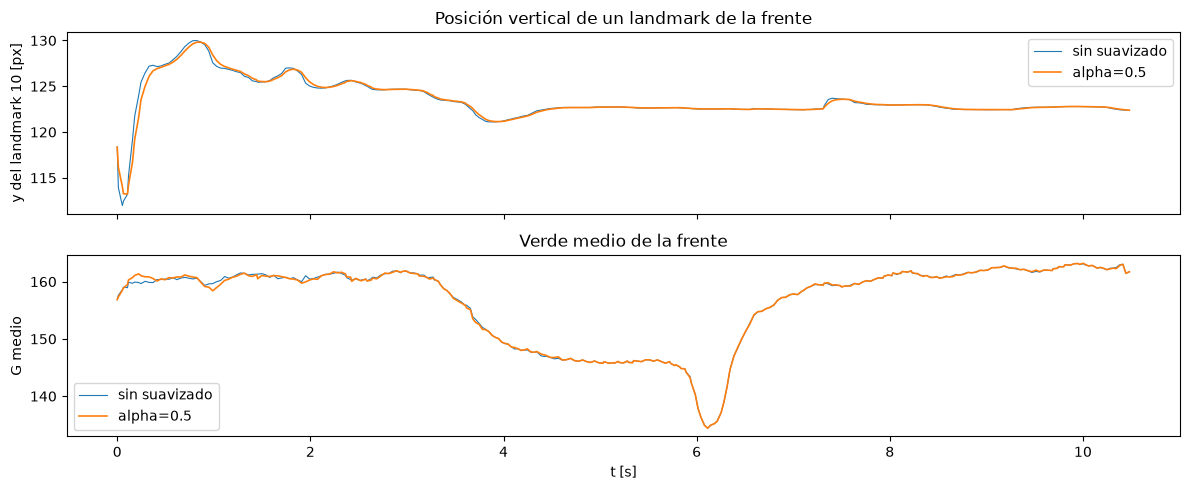

In [4]:
def run_detector(subject, n_frames, smoothing):
    gt = ds.ground_truth(subject)
    lms, greens = [], []
    with VideoLandmarker(model, smoothing=smoothing) as detector:
        for i, frame in enumerate(islice(ds.frames(subject), n_frames)):
            lm = detector(frame, gt.t[i])
            lms.append(lm)
            greens.append(roi_means(frame, lm, {"forehead": ROIS["forehead"]})[0][0, 1])
    return np.stack(lms), np.array(greens)

alpha = cfg["detector"]["landmark_smoothing"]
raw_lm, raw_g = run_detector("subject12", 300, 1.0)
smooth_lm, smooth_g = run_detector("subject12", 300, alpha)

LM = 10  # landmark del centro de la frente
jitter = lambda lm: np.linalg.norm(np.diff(lm[:, LM], axis=0), axis=1)
comparison = pd.DataFrame({
    "desplazamiento medio del landmark 10 [px/frame]": [jitter(raw_lm).mean(), jitter(smooth_lm).mean()],
    "std de la diferencia del verde [niveles/frame]": [np.diff(raw_g).std(), np.diff(smooth_g).std()],
}, index=["sin suavizado (alpha=1)", f"con suavizado (alpha={alpha})"])
display(comparison.round(3))

t = gt.t[:300]
fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
ax[0].plot(t, raw_lm[:, LM, 1], lw=0.8, label="sin suavizado")
ax[0].plot(t, smooth_lm[:, LM, 1], lw=1.2, label=f"alpha={alpha}")
ax[0].set(ylabel="y del landmark 10 [px]", title="Posición vertical de un landmark de la frente")
ax[0].legend()
ax[1].plot(t, raw_g, lw=0.8, label="sin suavizado")
ax[1].plot(t, smooth_g, lw=1.2, label=f"alpha={alpha}")
ax[1].set(xlabel="t [s]", ylabel="G medio", title="Verde medio de la frente")
ax[1].legend()
plt.tight_layout()

**Lectura:** con `alpha = 0.5`, el efecto es despreciable en ambas métricas: el temblor del landmark baja apenas y el ruido del verde no cambia. Los landmarks de MediaPipe en modo VIDEO ya son estables (el desplazamiento entre frames es de ~0,4 px). En el gráfico de abajo se ve lo que sí domina: el verde de la frente cambia ~25 niveles en t ≈ 6 s por movimiento o iluminación, muchas veces más que el temblor.

Conclusión: el suavizado queda configurable y no es la palanca importante. Lo que importa es la robustez frente al movimiento y la iluminación: CHROM y POS (v0.2.0). Ahí se vuelve a evaluar `alpha` midiendo directamente el MAE de HR.

## 2. ROIs de piel y recortes (`roi.py`)

### 2.1 Las ROIs en distintos sujetos

Polígonos de frente y mejillas definidos por índices de landmarks (`rois` en la config). Evitan ojos, cejas, nariz, boca y pelo. Como dependen de los landmarks, siguen a la cara cuando se mueve y se adaptan a cada rostro.

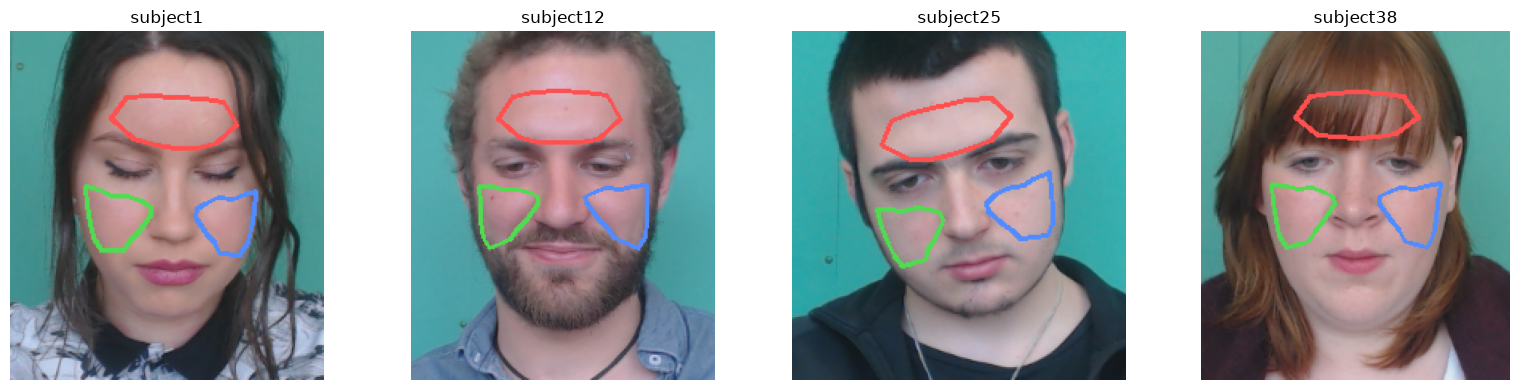

In [5]:
def first_landmarks(subject, frame_idx=60):
    gt = ds.ground_truth(subject)
    with VideoLandmarker(model) as detector:
        for i, frame in enumerate(islice(ds.frames(subject), frame_idx + 1)):
            lm = detector(frame, gt.t[i])
    return frame, lm

def draw_rois(frame, lm, mask=None):
    out = frame.copy()
    for name, idx in ROIS.items():
        cv2.polylines(out, [np.round(lm[idx]).astype(np.int32)], True, ROI_COLORS[name], 2)
    return out

showcase = ["subject1", "subject12", "subject25", "subject38"]
samples = {s: first_landmarks(s) for s in showcase}
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (s, (frame, lm)) in zip(axes, samples.items()):
    x0, y0 = (lm.min(axis=0) - 40).astype(int).clip(0)
    x1, y1 = (lm.max(axis=0) + 40).astype(int)
    ax.imshow(draw_rois(frame, lm)[y0:y1, x0:x1])
    ax.set_title(s)
    ax.axis("off")
plt.tight_layout()

### 2.2 Color medio por ROI

`roi_means` devuelve, para cada ROI, el color medio RGB y la cantidad de píxeles. Trabaja sobre la caja que contiene cada polígono y no sobre el frame entero, por eso es rápido. Si una ROI queda fuera de cuadro, devuelve NaN.

En piel, el orden de los canales es R > G > B. La pulsación se ve sobre todo en G, porque la hemoglobina absorbe mucho en el verde.

In [6]:
frame, lm = samples["subject1"]
means, counts = roi_means(frame, lm, ROIS)
pd.DataFrame(np.column_stack([means.round(1), counts]), index=list(ROIS),
             columns=["R", "G", "B", "píxeles"]).astype({"píxeles": int})

,R,G,B,píxeles
forehead,201.3,155.4,152.7,2070
left_cheek,189.9,145.2,144.9,1162
right_cheek,186.3,142.0,141.3,1069


### 2.3 Máscara de piel opcional

En sujetos con barba (subject12), el borde inferior de las mejillas la roza. `skin_mask` umbraliza en el espacio YCrCb y, si `skin_mask.enabled` está activo en la config, se interseca con cada ROI y descarta los píxeles que no son piel. Por defecto está desactivada: primero hay que medir si mejora la señal. Eso queda para cuando estén los métodos rPPG.

,píxeles ROI,píxeles de piel,fracción conservada
forehead,2388,2107,0.882
left_cheek,1205,1116,0.926
right_cheek,1274,1178,0.925


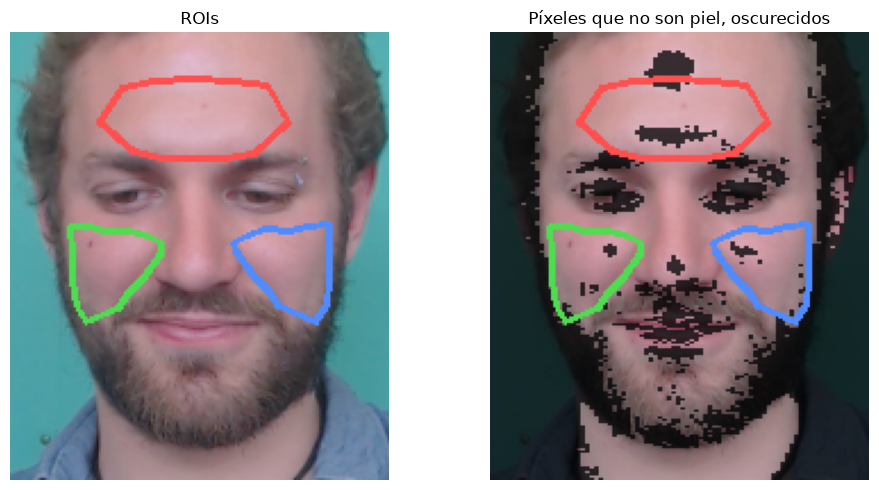

In [7]:
frame, lm = samples["subject12"]
sk = cfg["skin_mask"]
skin = skin_mask(frame, sk["cr_range"], sk["cb_range"])
_, n_all = roi_means(frame, lm, ROIS)
_, n_skin = roi_means(frame, lm, ROIS, skin)

x0, y0 = (lm.min(axis=0) - 20).astype(int)
x1, y1 = (lm.max(axis=0) + 20).astype(int)
overlay = frame.copy()
overlay[~skin] = (overlay[~skin] * 0.25).astype(np.uint8)
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(draw_rois(frame, lm)[y0:y1, x0:x1])
ax[0].set_title("ROIs")
ax[1].imshow(draw_rois(overlay, lm)[y0:y1, x0:x1])
ax[1].set_title("Píxeles que no son piel, oscurecidos")
for a in ax:
    a.axis("off")
plt.tight_layout()
pd.DataFrame({"píxeles ROI": n_all, "píxeles de piel": n_skin,
              "fracción conservada": (n_skin / n_all).round(3)}, index=list(ROIS))

**Lectura:** la máscara descarta píxeles de barba en el borde de las mejillas y, además, los brillos especulares de la frente (manchas oscuras dentro del polígono rojo). En este frame conserva ~90 % de los píxeles de cada ROI. Si conviene activarla se decide midiendo el MAE de HR con y sin máscara en la v0.2.0.

### 2.4 Recortes de cara para el DL

`face_crop` arma un cuadrado centrado en la cara, de lado `crops.scale` veces el lado mayor de la caja de landmarks, y lo redimensiona a `crops.size`. Si el cuadrado se sale del frame, rellena replicando el borde, así la cara no se deforma. Estos recortes son la entrada del modelo de DL. Pesan mucho menos que el video: se pueden subir a Drive para entrenar en Colab.

Frame original: 0.92 MB · recorte: 0.049 MB (19x menos, antes de comprimir)


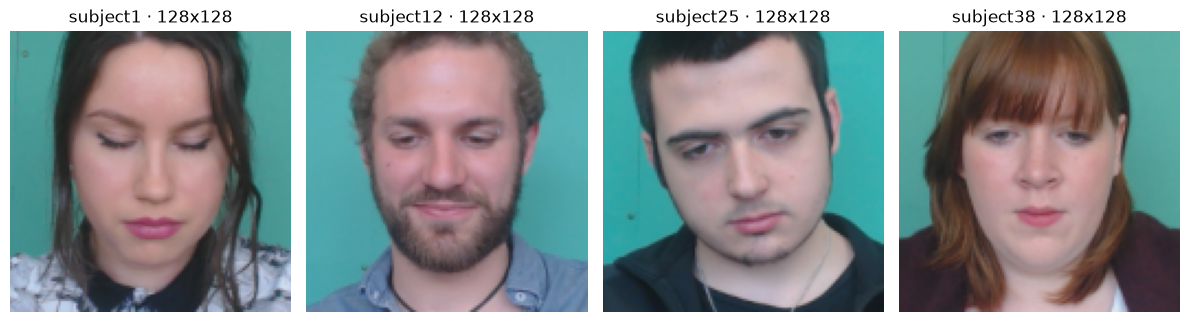

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
for ax, (s, (frame, lm)) in zip(axes, samples.items()):
    crop = face_crop(frame, lm, cfg["crops"]["size"], cfg["crops"]["scale"])
    ax.imshow(crop)
    ax.set_title(f"{s} · {crop.shape[1]}x{crop.shape[0]}")
    ax.axis("off")
plt.tight_layout()

frame_mb = 640 * 480 * 3 / 1e6
crop_mb = cfg["crops"]["size"] ** 2 * 3 / 1e6
print(f"Frame original: {frame_mb:.2f} MB · recorte: {crop_mb:.3f} MB "
      f"({frame_mb / crop_mb:.0f}x menos, antes de comprimir)")

## 3. Extracción de un video (`extract.py`)

`extract_video` recorre un video una sola vez. En cada frame detecta, calcula el color medio de cada ROI y, si se pide, recorta la cara.

Recibe el detector como parámetro, y eso tiene dos ventajas:
- en los tests se le pasa un detector falso con landmarks conocidos;
- acá se puede pasar el real.

Devuelve un `FaceTrack` con:
- `rgb (T, R, 3)`: NaN en los frames sin cara;
- `n_pixels (T, R)`;
- `detected (T,)`;
- `crops (T, S, S, 3)`.

Ejemplo con los primeros 20 s de un video:

In [9]:
subject = "subject1"
gt = ds.ground_truth(subject)
n = int(20 * FS)
with VideoLandmarker(model, smoothing=cfg["detector"]["landmark_smoothing"]) as detector:
    track = extract_video(islice(ds.frames(subject), n), gt.t[:n], detector, ROIS,
                          crop_size=cfg["crops"]["size"], crop_scale=cfg["crops"]["scale"])
print(f"rgb {track.rgb.shape} · n_pixels {track.n_pixels.shape} · crops {track.crops.shape}")
print(f"Tasa de detección: {track.detection_rate:.1%}")

rgb (600, 3, 3) · n_pixels (600, 3) · crops (600, 128, 128, 3)
Tasa de detección: 100.0%


## 4. Resultado de `scripts/extract_traces.py` sobre todo el dataset

El script aplica `extract_video` a los 42 videos y guarda dos archivos por sujeto en `data/processed/ubfc_rppg/<subject>/`:
- `traces.npz`, para el clásico;
- `crops.npz`, para el DL.

Si la configuración no cambió, los sujetos ya procesados se saltean: la cache guarda el hash de `configs/face.yaml`. También escribe `extraction_summary.csv`, con dos requerimientos del plan:
- **detección facial en ≥ 95 % de los frames**;
- **≤ 2 min de procesamiento por minuto de video**.

Sujetos procesados: 42 de 42
Detección: mínimo 100.00%, sujetos < 95 %: 0
Procesamiento por minuto de video: mediana 48 s, máximo 50 s (requerimiento: ≤ 120 s)
Espacio en disco: 3.20 GB en total, ~78 MB por sujeto


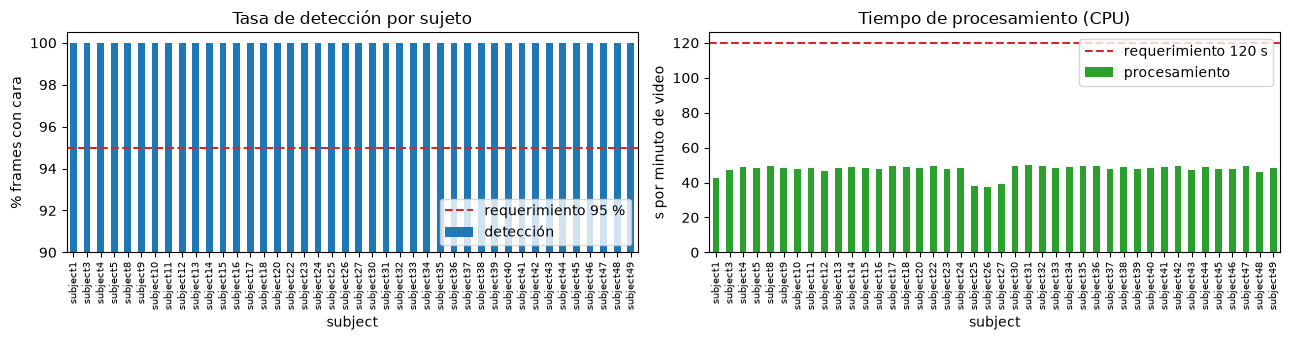

In [10]:
summary_path = ROOT / cfg["output_dir"] / cfg["dataset"]["name"] / "extraction_summary.csv"
summary = pd.read_csv(summary_path, index_col="subject")
print(f"Sujetos procesados: {len(summary)} de {len(ds.subjects())}")
print(f"Detección: mínimo {summary.detection_rate.min():.2%}, "
      f"sujetos < 95 %: {(summary.detection_rate < 0.95).sum()}")
print(f"Procesamiento por minuto de video: mediana {summary.processing_s_per_video_min.median():.0f} s, "
      f"máximo {summary.processing_s_per_video_min.max():.0f} s (requerimiento: ≤ 120 s)")
folder_mb = {s: sum(f.stat().st_size for f in (summary_path.parent / s).glob("*.npz")) / 1e6
             for s in summary.index}
print(f"Espacio en disco: {sum(folder_mb.values()) / 1e3:.2f} GB en total, "
      f"~{np.median(list(folder_mb.values())):.0f} MB por sujeto")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
summary.detection_rate.mul(100).plot.bar(ax=ax[0], color="tab:blue", label="detección")
ax[0].axhline(95, color="tab:red", ls="--", label="requerimiento 95 %")
ax[0].set(ylim=(90, 100.5), ylabel="% frames con cara", title="Tasa de detección por sujeto")
ax[0].legend(loc="lower right")
summary.processing_s_per_video_min.plot.bar(ax=ax[1], color="tab:green", label="procesamiento")
ax[1].axhline(120, color="tab:red", ls="--", label="requerimiento 120 s")
ax[1].set(ylabel="s por minuto de video", title="Tiempo de procesamiento (CPU)")
ax[1].legend(loc="upper right")
for a in ax:
    a.tick_params(axis="x", labelsize=7)
plt.tight_layout()

### 4.1 Trazas guardadas

`load_traces` lee solo las trazas, sin los recortes, que son pesados y solo los usa el DL. Así se ven las tres ROIs de un sujeto. Cada curva está normalizada por su media, para comparar la variación relativa entre ROIs.

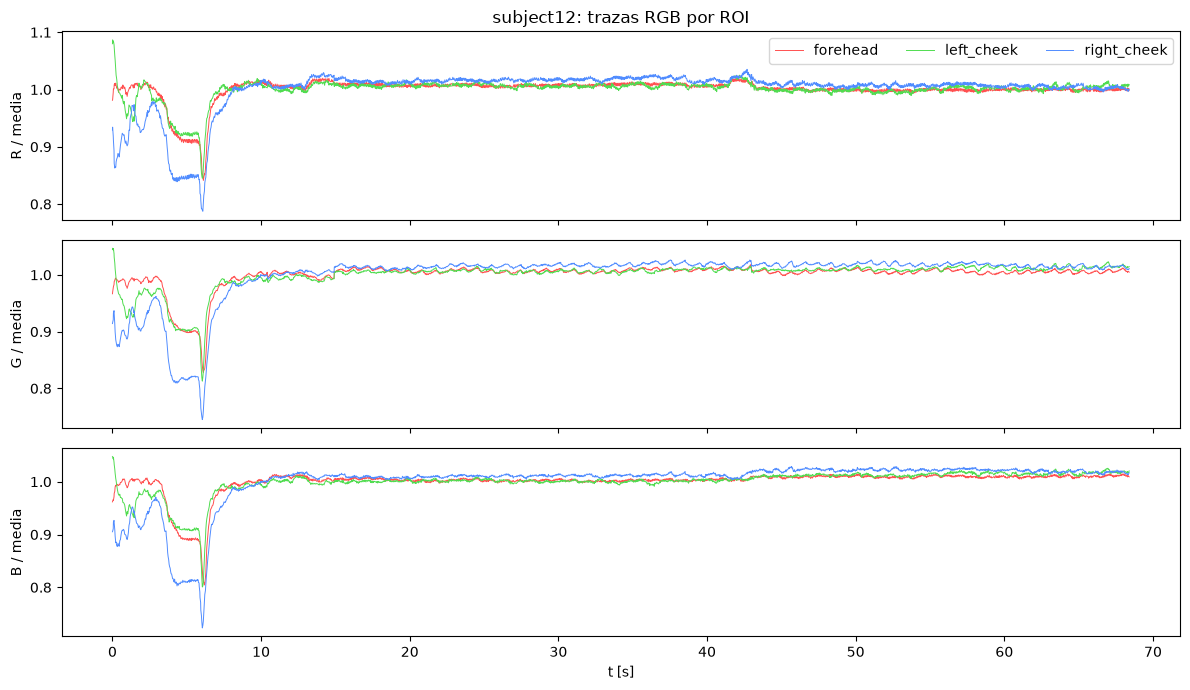

In [11]:
subject = "subject12"
tr = load_traces(summary_path.parent / subject)
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
for c, (ax, channel) in enumerate(zip(axes, "RGB")):
    for r, name in enumerate(tr.roi_names):
        x = tr.rgb[:, r, c]
        ax.plot(tr.t, x / np.nanmean(x), lw=0.7, label=name, color=np.array(ROI_COLORS[name]) / 255)
    ax.set_ylabel(f"{channel} / media")
axes[0].legend(loc="upper right", ncol=3)
axes[0].set_title(f"{subject}: trazas RGB por ROI")
axes[-1].set_xlabel("t [s]")
plt.tight_layout()

## 5. Primer vistazo: HR desde el canal verde

Esto **no** es el baseline oficial: falta combinar las ROIs y aplicar CHROM y POS, que vienen en la próxima rama. Sirve para comprobar que las trazas tienen pulso.

Se toma el verde de la frente y se le aplica **el mismo** post-procesamiento que a la PPG de referencia (`rppg.dsp`). Se comparan ventana a ventana, con ventanas de 10 s y paso de 1 s (D3).

In [12]:
def window_hr(t, x, valid=None):
    u = resample_uniform(t, x, FS, max_gap_s=0.5)
    y = bandpass(u.x, FS, *HR_BAND)
    return estimate_rate(y, FS, HR_BAND, 10, 1, valid=u.valid, nfft=4096)

rows, examples = [], {}
for s in summary.index:
    tr = load_traces(summary_path.parent / s)
    gt = ds.ground_truth(s)
    est = window_hr(tr.t, tr.rgb[:, tr.roi_names.index("forehead"), 1])
    ref = window_hr(gt.t, gt.ppg)
    n = min(len(est.rate_per_min), len(ref.rate_per_min))
    rows.append({"subject": s, **summarize(est.rate_per_min[:n], ref.rate_per_min[:n])})
    examples[s] = (est, ref)
per_subject = pd.DataFrame(rows).set_index("subject")
all_est = np.concatenate([examples[s][0].rate_per_min[:per_subject.n[s]] for s in per_subject.index])
all_ref = np.concatenate([examples[s][1].rate_per_min[:per_subject.n[s]] for s in per_subject.index])
overall = summarize(all_est, all_ref)
print(f"GREEN (frente) vs referencia, todas las ventanas: MAE {overall['mae']:.1f} bpm · "
      f"RMSE {overall['rmse']:.1f} bpm · Pearson {overall['pearson']:.2f} · n={overall['n']}")
print(f"Sujetos con MAE ≤ 5 bpm: {(per_subject.mae <= 5).sum()} de {len(per_subject)}")
per_subject.round(2).sort_values("mae").T

GREEN (frente) vs referencia, todas las ventanas: MAE 11.1 bpm · RMSE 22.7 bpm · Pearson 0.53 · n=2308
Sujetos con MAE ≤ 5 bpm: 24 de 42


subject,subject31,subject25,subject8,subject47,subject42,subject17,subject33,subject1,subject39,subject13,...,subject34,subject41,subject49,subject15,subject48,subject5,subject10,subject38,subject20,subject11
mae,0.33,0.33,0.36,0.38,0.46,0.54,0.54,0.58,0.70,0.70,...,21.35,22.52,24.57,25.37,28.97,30.03,34.37,44.11,44.61,55.12
rmse,0.44,0.42,0.78,0.46,0.54,0.63,0.75,0.78,0.87,0.87,...,36.48,31.74,26.81,36.15,31.70,37.69,39.32,45.35,57.27,60.51
pearson,0.98,0.98,0.97,1.00,0.99,0.97,0.97,0.95,0.92,0.99,...,0.17,0.11,0.44,0.45,0.23,-0.66,-0.15,0.28,0.04,-0.10
n,59.00,47.00,58.00,58.00,59.00,59.00,54.00,43.00,59.00,58.00,...,58.00,59.00,59.00,48.00,59.00,43.00,58.00,59.00,59.00,59.00


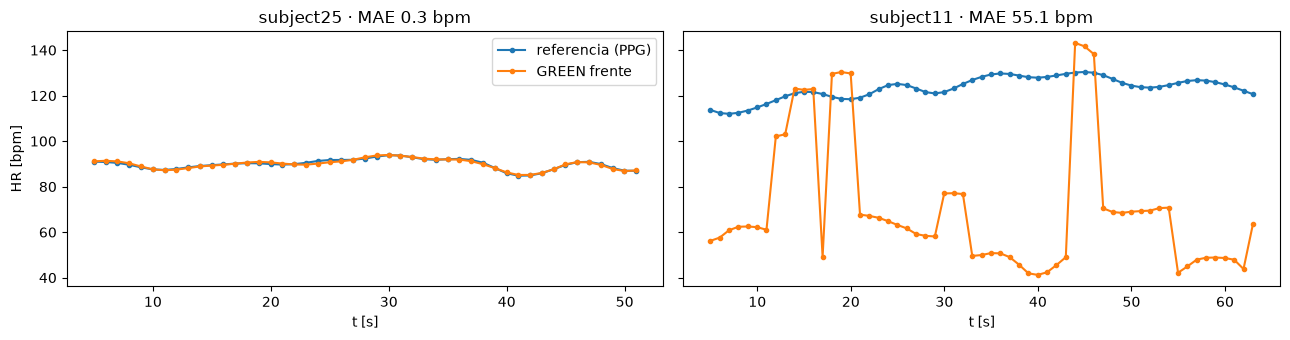

In [13]:
best, worst = per_subject.mae.idxmin(), per_subject.mae.idxmax()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5), sharey=True)
for ax, s in zip(axes, [best, worst]):
    est, ref = examples[s]
    ax.plot(ref.t_center, ref.rate_per_min, "o-", ms=3, label="referencia (PPG)")
    ax.plot(est.t_center, est.rate_per_min, "o-", ms=3, label="GREEN frente")
    ax.set(title=f"{s} · MAE {per_subject.mae[s]:.1f} bpm", xlabel="t [s]")
axes[0].set_ylabel("HR [bpm]")
axes[0].legend()
plt.tight_layout()

**Lectura:** con el método más simple (verde de una sola ROI, sin CHROM ni POS) ya se ve el pulso en las trazas. Los errores grandes de algunos sujetos son esperables en este baseline. El canal verde solo es sensible a los cambios de iluminación y a los movimientos. CHROM y POS (próxima rama, v0.2.0) se diseñaron justamente para eso, y ahí se mide el baseline de verdad con el protocolo de evaluación común.